# GenMol - Basics

## Setup
This notebook assumes that the NIM is running! Ports for the NIMs:
- AlphaFold2: 8081
- MolMIM: 8082
- **GenMOL: 8083**
- diffdock : 8084


In [1]:
!pip install safe-mol datamol pandas numpy rdkit matplotlib 2>/dev/null | tail -n 1

In [2]:
#!pip install safe-mol datamol 2>/dev/null | tail -n 1

In [2]:
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.utils import Utils

from rdkit import Chem
from rdkit.Chem import Draw

# SAFE <> SMILES conversion
import safe as sf
import datamol as dm

import pandas as pd

GENMOL_HOST = 'http://127.0.0.1:8083'
gm = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")


## Test NIM availability

In [3]:
!curl {GENMOL_HOST}/v1/health/ready

true

## Define Seeds and used Seed for generation

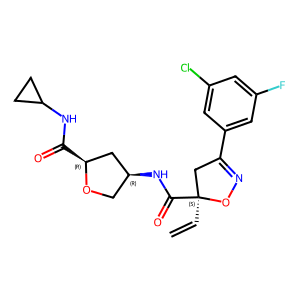

In [4]:
#Seed 1
m1 = "C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)NC3CC3)C2)CC(c2cc(F)cc(Cl)c2)=NO1"
m1_name = "BCS-DR81962"

seed_mol_m1  = dm.to_mol(m1)
display(dm.to_image(seed_mol_m1))

In [5]:
# define the seed to be used in the notebook
m_seq = m1
seed_mol = seed_mol_m1

## check SAFE conversion & Reconstruction

In [6]:
safe_str = sf.encode(seed_mol)
print(f"SMILES: {m_seq}")
print(f"SAFE:   {safe_str}\n represented using {len(safe_str.split('.'))} fragments")

SMILES: C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)NC3CC3)C2)CC(c2cc(F)cc(Cl)c2)=NO1
SAFE:   C=C[C@]18CC(c2cc(F)cc(Cl)c2)=NO1.[C@H]16CO[C@@H]9C1.C48=O.C59=O.C17CC1.N46.N57
 represented using 7 fragments


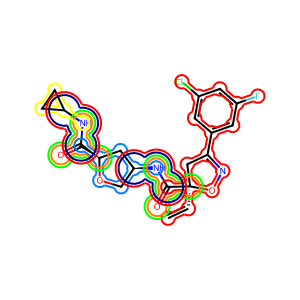

In [7]:
sf.to_image(safe_str)

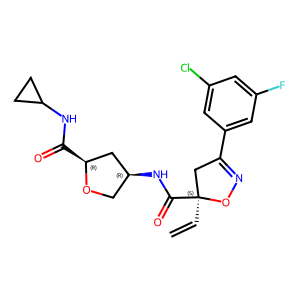

In [8]:
testreconstructed = dm.to_mol(safe_str)
display(dm.to_image(testreconstructed))

# Base Generation

Just a test generation to see if model is woring... basically the "de novo" way to generate molecules

In [9]:
result = gm.produce([m_seq], 10)

In [10]:
print(result[0])
print(m_seq)

C[NH+]1CC[C@@H](NC(=O)c2ccc(CC(=O)N3CCC(C)(C)C3)cc2)C1
C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)NC3CC3)C2)CC(c2cc(F)cc(Cl)c2)=NO1


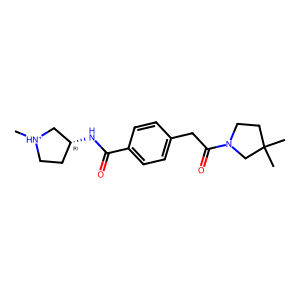

In [11]:
res_mol  = dm.to_mol(result[0])
display(dm.to_image(res_mol))

# Motif-Extension or Scaffold-Decoration

input is single fragment

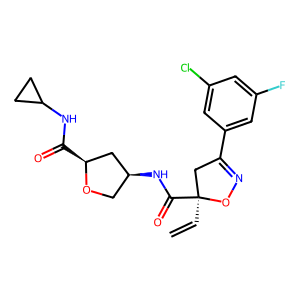

In [12]:
#draw original mol
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

### Example 1: first fragment

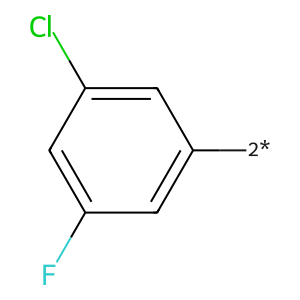

In [13]:
# add wildcard to a fragment
smiles_masked_1 = '[2*]C1=CC(F)=CC(Cl)=C1'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [14]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules_e1 = gm.inference(smiles = safe_to_gen + '.[*{8-20}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e1)

15

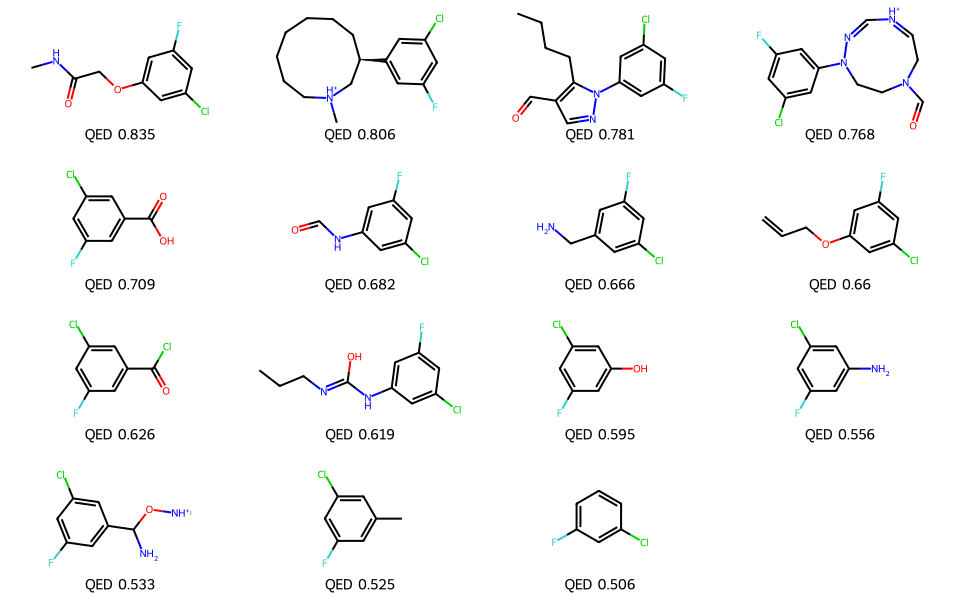

In [15]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e1]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e1])

In [16]:
# Create a DataFrame + add results
df_results = pd.DataFrame(molecules_e1)

## Example 2: second fragment

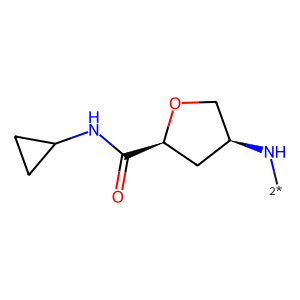

In [18]:
# add wildcard to a fragment
smiles_masked_2 = '[2*]N[C@@H]1CO[C@@H](C1)C(=O)NC1CC1' 
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_2))

In [19]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_2)
safe_to_gen
molecules_e2 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e2)

25

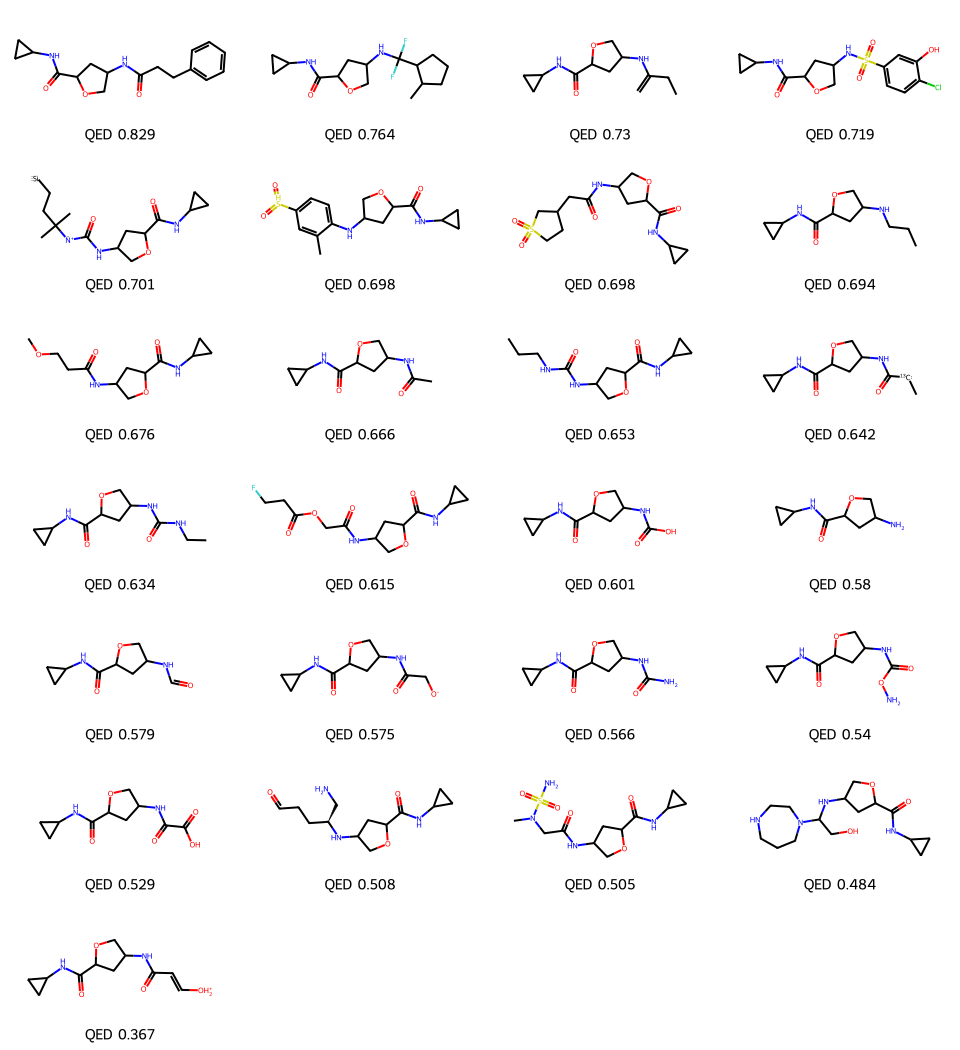

In [20]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e2]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e2])

In [21]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e2)], ignore_index=True)

In [22]:
len(df_results)

40

## Example 3: third fragment

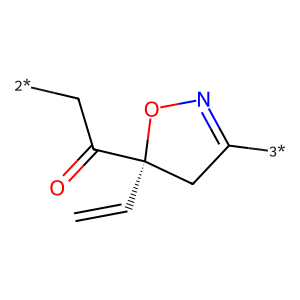

In [28]:
# add wildcard to a fragment
smiles_masked_3 = '[2*]CC(=O)[C@@]1(CC([3*])=NO1)C=C'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_3))

In [31]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_3)
safe_to_gen
molecules_e3 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e3)

58

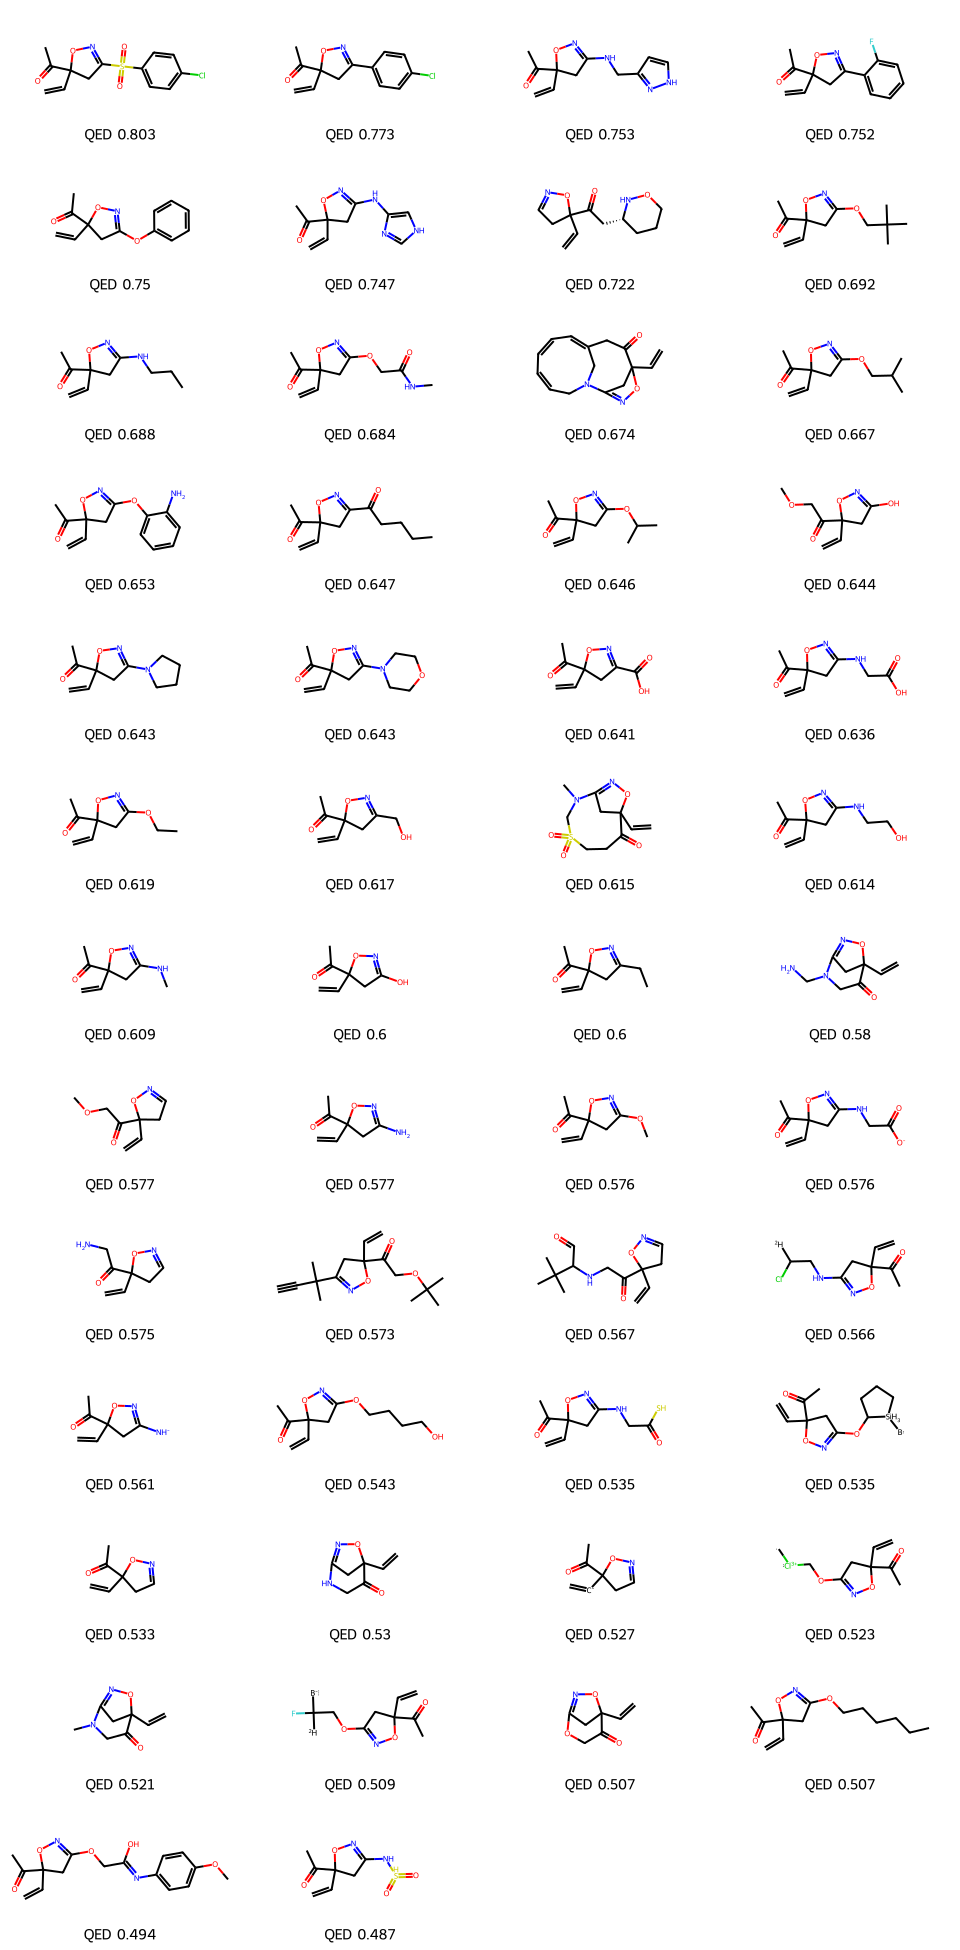

In [36]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e3]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e3])

In [38]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e3)], ignore_index=True)

In [39]:
len(df_results)

98

# Fragment based generation 
(Linker generation / Scaffold morphing)

## Mask at the end

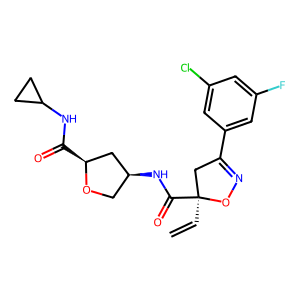

In [40]:
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

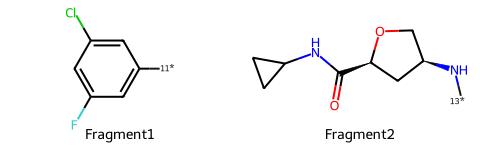

In [43]:
frag1, frag2 = '[11*]C1=CC(F)=CC(Cl)=C1', '[13*]N[C@@H]1CO[C@@H](C1)C(=O)NC1CC1'

Draw.MolsToGridImage([Chem.MolFromSmiles(frag1), Chem.MolFromSmiles(frag2)], 
                      molsPerRow=2, subImgSize=(240, 150), legends=['Fragment1', 'Fragment2'])

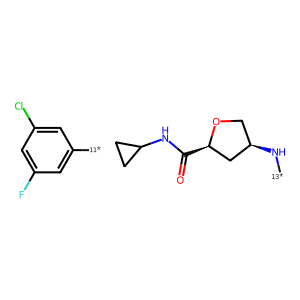

In [44]:
smiles_joint = '.'.join([frag1, frag2])
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [45]:
# mask at the end
input_text = Utils.smiles2safe(smiles_joint) + '.[*{5-20}]'
input_text

'c12cc(F)cc(Cl)c1.C15COC7C1.C47=O.C16CC1.N35.N46.[*{5-20}]'

In [49]:
molecules_e4 = gm.inference(smiles=input_text, temperature =2.0, noise =1.0, num_molecules=1000, step_size=1)
len(molecules_e4)

2

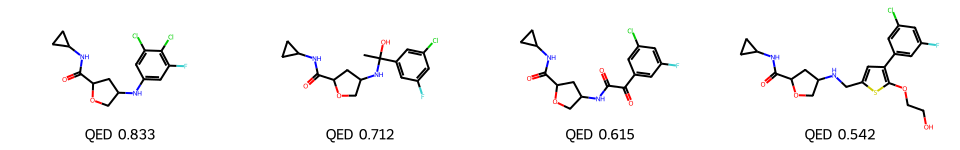

In [47]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e4]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e4])

In [48]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e4)], ignore_index=True)
print(len(df_results))
df_results.head()

102


,smiles,score
0,CNC(=O)COc1cc(F)cc(Cl)c1,0.835
1,C[NH+]1CCCCCCC[C@@H](c2cc(F)cc(Cl)c2)C1,0.806
2,CCCCc1c(C=O)cnn1-c1cc(F)cc(Cl)c1,0.781
3,O=CN1CC=[NH+]C=NN(c2cc(F)cc(Cl)c2)CC1,0.768
4,O=C(O)c1cc(F)cc(Cl)c1,0.709


## Mask in the center

[11*]C1=CC(F)=CC(Cl)=C1.[13*]N[C@@H]1CO[C@@H](C1)C(=O)NC1CC1


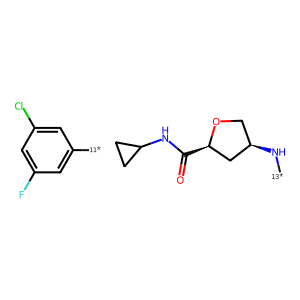

In [50]:
smiles_joint = '.'.join([frag1, frag2])
print(smiles_joint)
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [51]:
#what sub-fragments are in frag1 
text_frag1 = Utils.smiles2safe(frag1).split('.')
text_frag1

['c12cc(F)cc(Cl)c1']

In [52]:
#what sub-fragments are in frag2
text_frag2 = Utils.smiles2safe(frag2).split('.')
text_frag2

['C14COC6C1', 'C36=O', 'C15CC1', 'N24', 'N35']

In [59]:
#what sub-fragments are in the full mol?
input_text = Utils.smiles2safe(smiles_joint).split('.')
input_text

['c12cc(F)cc(Cl)c1', 'C15COC7C1', 'C47=O', 'C16CC1', 'N35', 'N46']

In [60]:
input_text[:1]

['c12cc(F)cc(Cl)c1']

In [61]:
# select where to set mask
input_w_mask = '.'.join(input_text[:1]) + '.[*{5-20}].' + '.'.join(input_text[1:])
input_w_mask

'c12cc(F)cc(Cl)c1.[*{5-20}].C15COC7C1.C47=O.C16CC1.N35.N46'

In [63]:
molecules_e5 = gm.inference(smiles = input_w_mask, temperature = 2.0, noise = 1.0, num_molecules=1000)
len(molecules_e5)

6

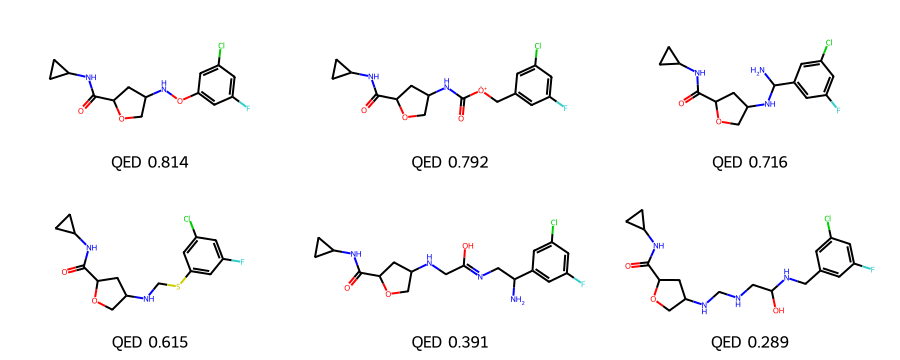

In [64]:
Draw.MolsToGridImage([Chem.MolFromSmiles(_['smiles']) for _ in molecules_e5[:12]], 
                      molsPerRow=3, subImgSize=(300, 180), legends=['QED ' + str(_['score']) for _ in molecules_e5[:12]])

In [65]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e5)], ignore_index=True)
print(len(df_results))
df_results.head()

108


,smiles,score
0,CNC(=O)COc1cc(F)cc(Cl)c1,0.835
1,C[NH+]1CCCCCCC[C@@H](c2cc(F)cc(Cl)c2)C1,0.806
2,CCCCc1c(C=O)cnn1-c1cc(F)cc(Cl)c1,0.781
3,O=CN1CC=[NH+]C=NN(c2cc(F)cc(Cl)c2)CC1,0.768
4,O=C(O)c1cc(F)cc(Cl)c1,0.709


In [66]:
#df_results.to_csv("../../data/interim/genmol/BCS-DR81962_R1_testmulti.csv", index=False)